** 1.Crosstab Analysis:**

In [15]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
5,6,B09B97WSLF,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
6,7,B09B9615X2,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
7,8,B01MTB55WH,Anker Soundcore 2 Portable Bluetooth Speaker w...,4.7,103673,39.99,False,0,Hi-Fi Speakers
8,9,B016MO90GW,"Bluetooth Speaker, Anker Soundcore Speaker Upg...",4.7,29909,29.99,False,0,Hi-Fi Speakers
9,10,B09ZQF5GZW,RIENOK Bluetooth Speaker Portable Wireless Blu...,4.5,16014,29.99,False,0,Hi-Fi Speakers


Create a crosstab between the product category and the isBestSeller status.

In [16]:
# numerical and categorical var
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


Are there categories where being a best-seller is more prevalent?

In [17]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [18]:
best_seller_rate = crosstab_result[True].sort_values(ascending=False)
best_seller_rate

category
Grocery                        556
Health & Personal Care         552
Baby                           341
Sports & Outdoors              330
Power & Hand Tools             306
                              ... 
Blank Media Cases & Wallets      0
Boating Footwear                 0
Boxes & Organisers               0
CD, Disc & Tape Players          0
eBook Readers & Accessories      0
Name: True, Length: 296, dtype: int64

Categories Grocery, Health &Personal care have highest bestsellers followed by Baby and Sport & Outdoors categories

** 2.Statistical Tests:**

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [19]:
from scipy.stats import chi2_contingency


chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_p_value

np.float64(0.0)

p-value 0.0 shows there is dependency between best-seller and product_category columns

Compute Cramér's V to understand the strength of association between best-seller status and category.

In [20]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

p ≈ 0 represents there is a real association between category and bestsellers
But Cramér’s V = 0.122 represents weak association

** 3.Visualizations:**

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

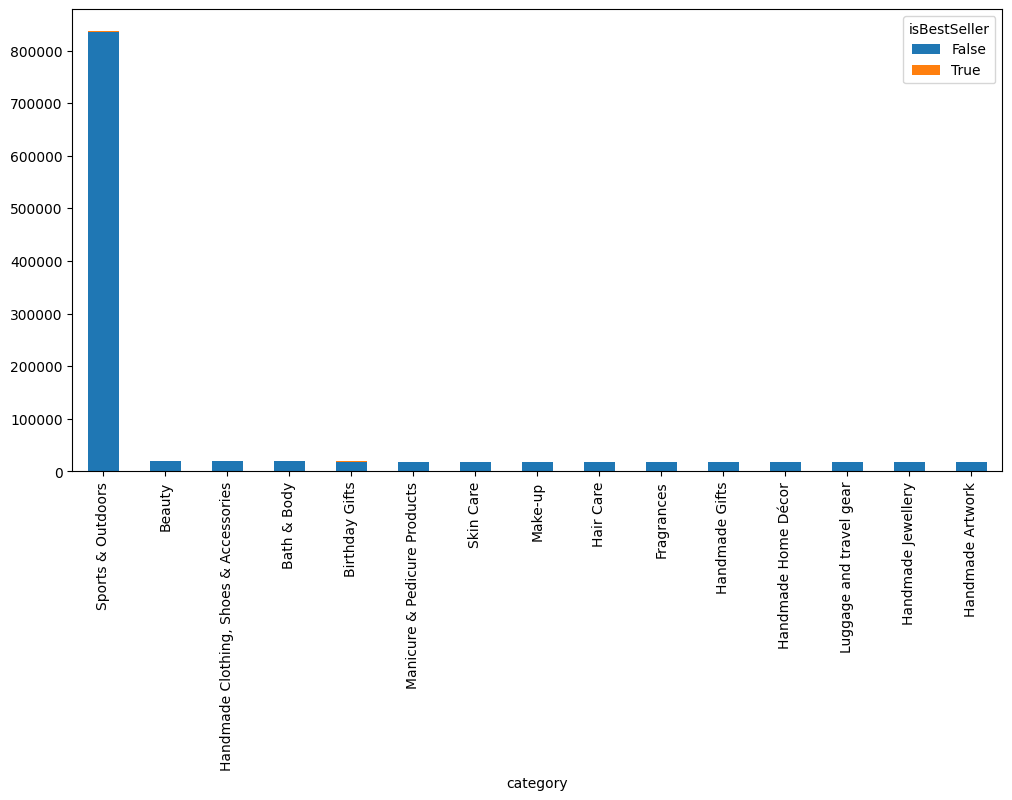

In [22]:

crosstab_pct = pd.crosstab(
    df['category'],
    df['isBestSeller']
)

# sort by total counts across both columns
sorted_crosstab = crosstab_pct.loc[
    crosstab_pct.sum(axis=1).sort_values(ascending=False).index
].head(15)

sorted_crosstab.plot(kind='bar', stacked=True, figsize=(12,6))

** 0. Preliminary Step: Remove outliers in product prices.**

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

In [23]:
# Q1 contain first quantile data
Q1 = df['price'].quantile(0.25)

# Q3 contain last quantile data
Q3 = df['price'].quantile(0.75)

# IQR will contain now just second quantile
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


**  1.Violin Plots:**

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

one categorical var-category, one numerical var-price

C:\Users\advik\AppData\Local\Temp\ipykernel_3128\869997077.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")


<Axes: xlabel='category', ylabel='price'>

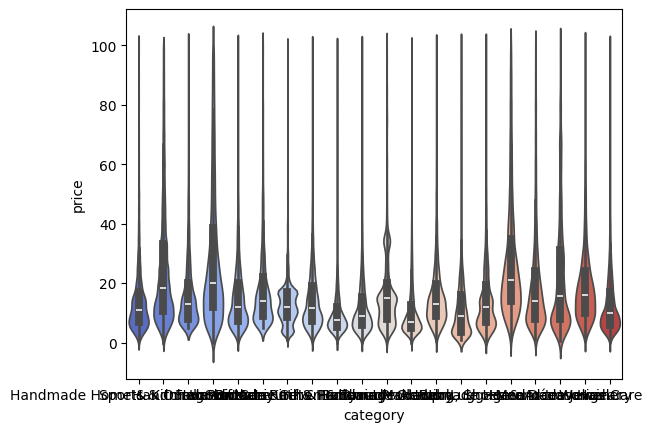

In [24]:
top20 = df_no_outliers['category'].value_counts().head(20).index

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20)]

sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")

C:\Users\advik\AppData\Local\Temp\ipykernel_3128\510643106.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top10, x='category', y='price', palette="coolwarm")


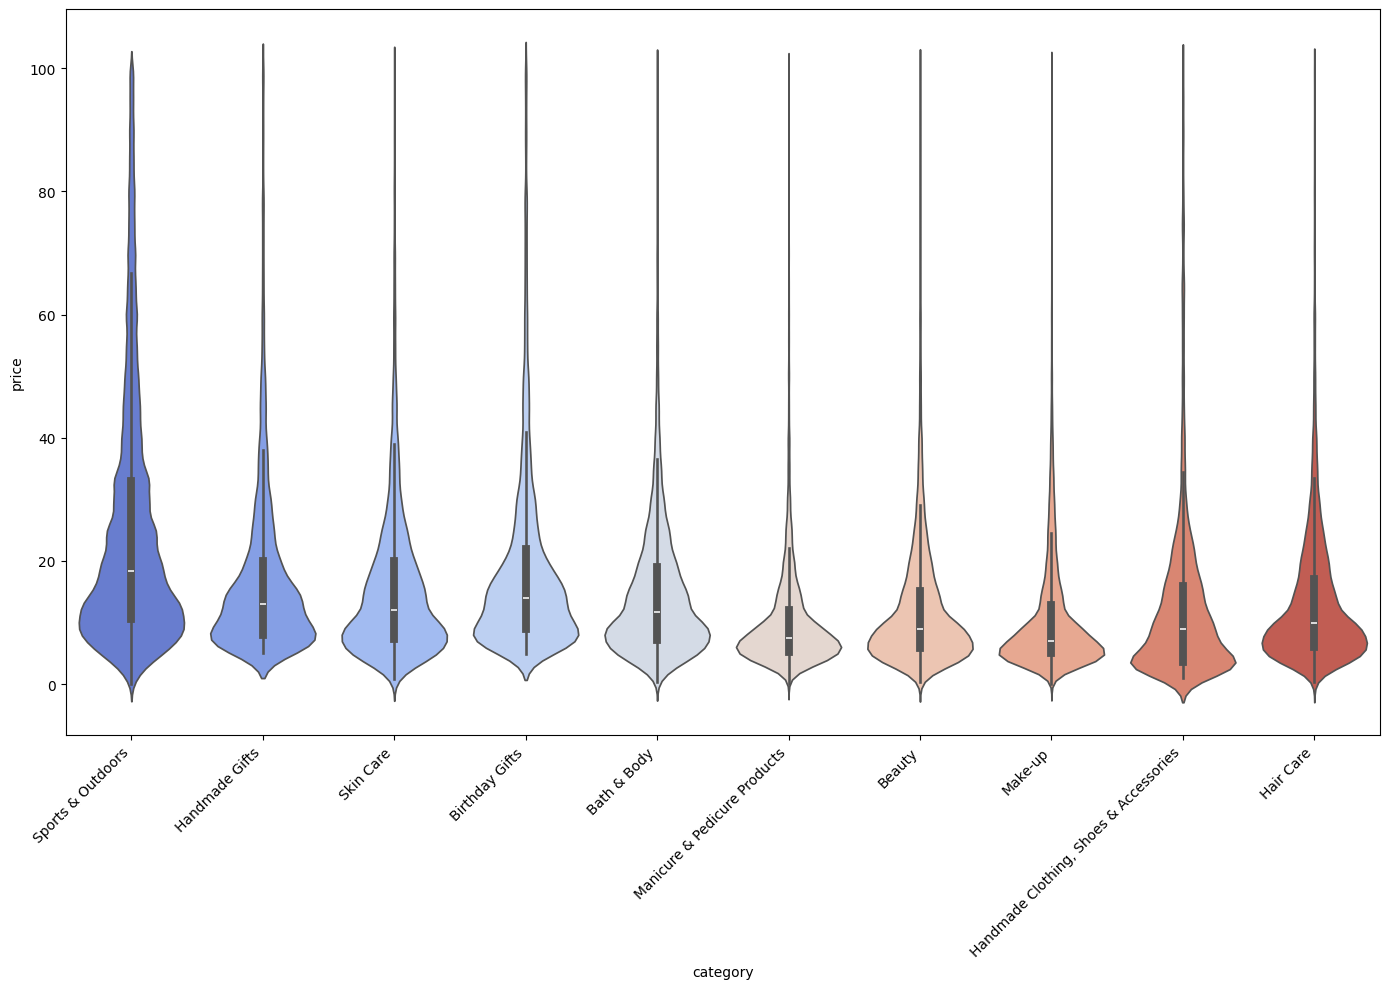

In [25]:
top10 = df_no_outliers['category'].value_counts().head(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10)]

plt.figure(figsize=(14, 10))

sns.violinplot(data=df_top10, x='category', y='price', palette="coolwarm")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

** 2.Bar Charts:**

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

<Axes: xlabel='category'>

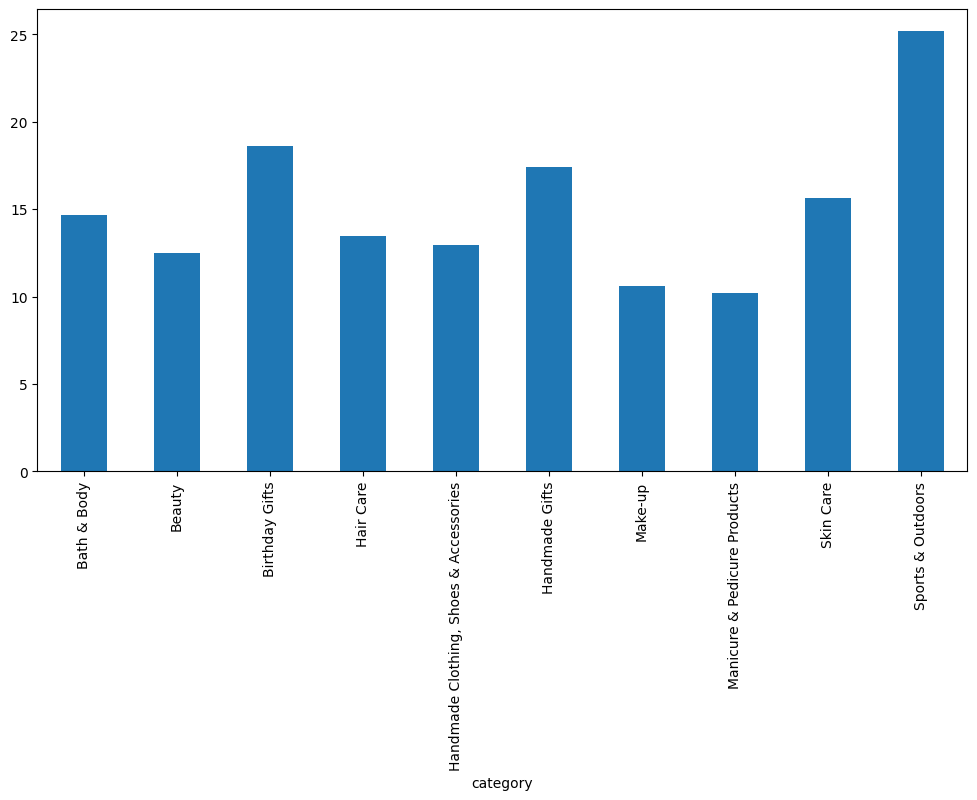

In [26]:
top10_categories = df_no_outliers['category'].value_counts().head(10).index

top10_df = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

avg_price = top10_df.groupby('category')['price'].mean()

avg_price = avg_price

avg_price.plot(kind='bar', figsize=(12,6))

Sports and outdoor has high average price

** 3.Box Plots:**

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [27]:
df_no_outliers.columns
crosstab_cat_rating = pd.crosstab(df_no_outliers['category'],
    df_no_outliers['stars'])
crosstab_cat_rating.sort_values(by='category').head(10)


stars,0.0,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,...,4.1,4.2,4.3,4.4,4.5,4.6,4.7,4.8,4.9,5.0
category,,,,,,,,,,,,,,,,,,,,,
3D Printers,12,0,0,0,0,0,0,0,0,0,...,2,2,5,2,3,3,1,0,0,1
3D Printing & Scanning,3183,0,0,0,0,0,0,0,0,0,...,5,5,6,16,9,5,6,0,0,9
Abrasive & Finishing Products,16,0,0,0,0,0,0,0,0,0,...,12,21,20,25,45,38,19,6,3,17
Action Cameras,702,6,0,0,0,0,1,0,3,0,...,15,13,10,15,12,22,9,1,0,28
Adapters,11,0,0,0,0,0,0,0,0,0,...,16,17,35,40,40,31,8,8,0,10
Agricultural Equipment & Supplies,291,22,0,0,1,0,1,0,0,1,...,523,706,949,1050,1179,866,489,223,56,306
Alexa Built-In Devices,0,0,0,0,0,0,0,0,0,0,...,7,8,10,4,1,1,0,0,0,0
Art & Craft Supplies,36,0,0,0,0,0,0,0,0,1,...,6,11,13,28,45,30,32,13,3,16
Arts & Crafts,99,7,0,0,0,0,1,0,0,0,...,288,472,796,1235,1697,2079,1596,419,83,209


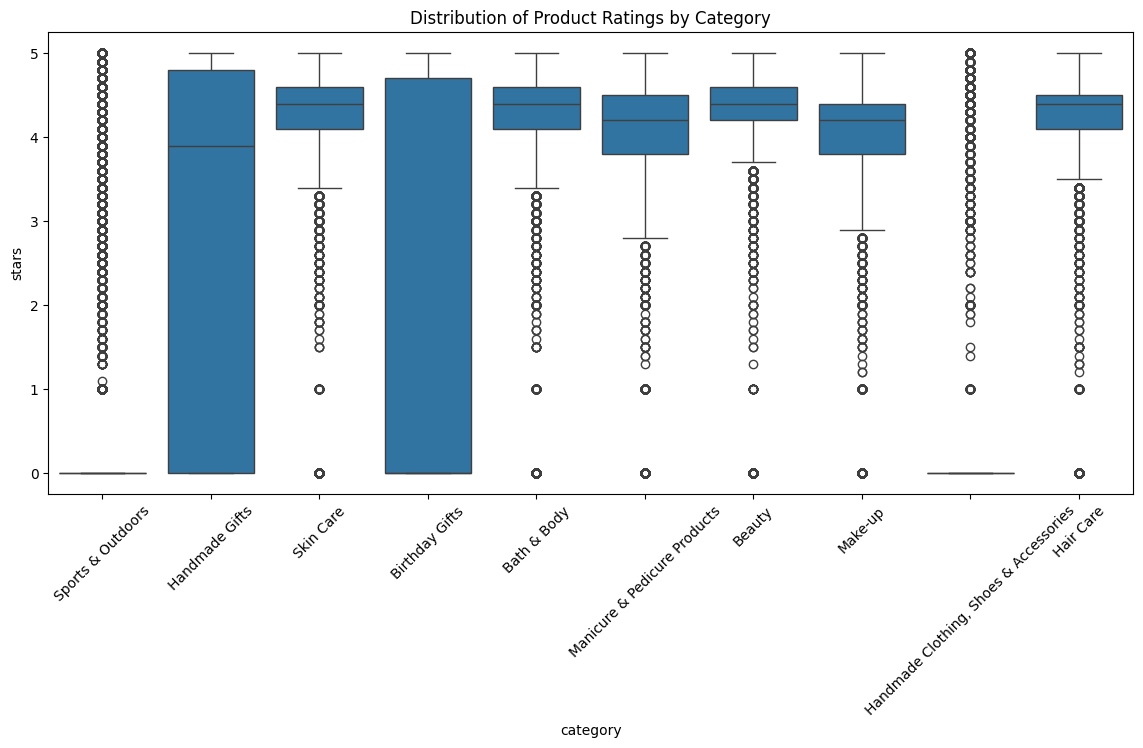

In [28]:
top10 = df_no_outliers['category'].value_counts().head(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10)]

plt.figure(figsize=(14,6))

df_sorted = df.sort_values(by='category').head(10)
sns.boxplot(
    data=df_top10,
    x='category',
    y='stars'
)

plt.xticks(rotation=45)
plt.title('Distribution of Product Ratings by Category')
plt.show()

In [29]:
# This will show you the exact median for every category
medians = df.groupby('category')['stars'].median().sort_values(ascending=False).head(30)
print(medians)

category
Computer Memory                        4.7
CPUs                                   4.6
Building & Construction Toys           4.6
Laptop Accessories                     4.6
Hobbies                                4.6
Kids' Play Figures                     4.6
Beer, Wine & Spirits                   4.6
Office Paper Products                  4.6
Luxury Food & Drink                    4.6
Children's Bedding                     4.5
Camera & Photo Accessories             4.5
Soft Toys                              4.5
Abrasive & Finishing Products          4.5
Tableware                              4.5
Boxes & Organisers                     4.5
Pens, Pencils & Writing Supplies       4.5
Dolls & Accessories                    4.5
Games & Game Accessories               4.5
Film Cameras                           4.5
Power & Hand Tools                     4.5
Jigsaws & Puzzles                      4.5
Health & Personal Care                 4.5
Photo Frames                           4.5
Ar

**Part 3: Investigating the Interplay Between Product Prices and Ratings**

**1. Correlation Coefficients:**

In [ ]:
Calculate the correlation coefficient between price and stars.

In [30]:
correlation_matrix = df_no_outliers[['price', 'stars']].corr()

print("correlation coefficient between price and stars: ",correlation_matrix)

correlation coefficient between price and stars:            price     stars
price  1.000000 -0.077673
stars -0.077673  1.000000


Is there a significant correlation between product price and its rating?

The negative sign (−) means:
- as price increases, stars tend to slightly decrease
- The magnitude (0.1249) is very small

- 0.12 → very weak correlation

**V2. isualizations:**

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?   

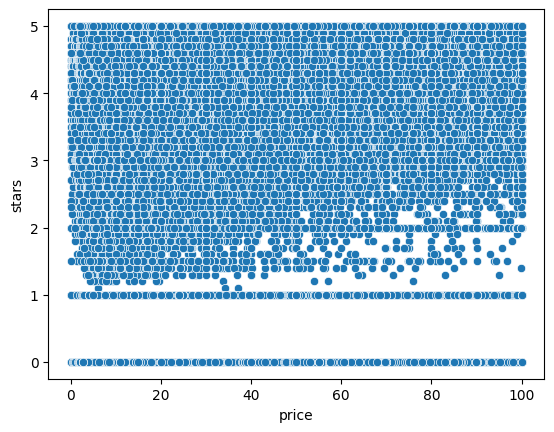

In [13]:
sns.scatterplot(data=df_no_outliers, x="price", y="stars")
plt.show()

Use a correlation heatmap to visualize correlations between all numerical variables.

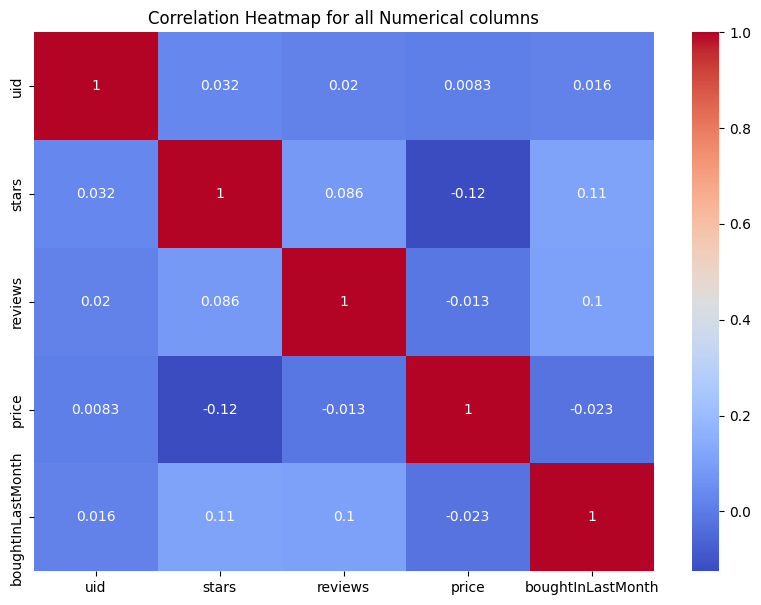

In [31]:
import numpy as np

numerical_cols = df.select_dtypes(include=np.number)

correlation_matrix = numerical_cols.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(10, 7))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for all Numerical columns")
plt.show()

Examine if product prices typically follow a normal distribution using a QQ plot.

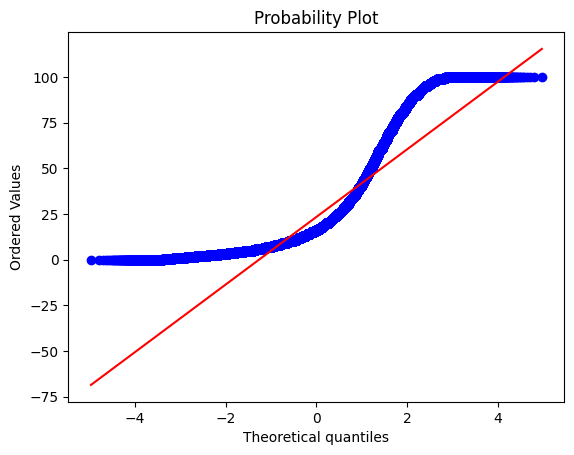

In [33]:
import scipy.stats as stats

stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.show()

Your product prices are not normally distributed.